# Fusion Equilibrium Challenge — Conv Decoder Training (FULL split, GPU)

Same `PsiConvDecoder` as `train_conv_decoder.ipynb`, but trains on the **entire** train/val
split (4929 train shots / 704 val shots) instead of a subsample -- matching exactly what the
Ridge/Random Forest/MLP baselines in `manifest.json` were trained on, so this run's `val R2` is
directly comparable to their 0.3967 / 0.7626 without a "but it only saw 40% of the data" caveat.

**Run this as a separate Colab instance from `train_conv_decoder.ipynb`** if you're iterating on
architecture there at the same time -- this notebook writes its checkpoint to a different file
(`flux_conv_decoder_full.pt`) so the two don't clobber each other.

Needs a GPU with real headroom: ψ targets are stored float16 on-GPU (~9GB at this scale) --
a 16GB+ card (T4/L4/A100) is required; this will not fit a small (<12GB) GPU at full scale.

Needs the Drive-synced `code/run/` and `code/artifacts/features/` (from local `00`/`01`) to
already exist -- this does NOT re-extract features, only trains a new model against the 01
cache's scaler/split/meta.

In [1]:
from google.colab import drive
drive.mount('/content/drive')
# torch ships with Colab already -- nothing to pip install for this notebook.


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
import sys
from pathlib import Path

FOLDER_NAME = "EXPERIMENTS/FEC_NeurIPS/code"
CODE_DIR = Path("/content/drive/MyDrive") / FOLDER_NAME
RUN_DIR = CODE_DIR / "run"
ARTIFACTS_DIR = CODE_DIR / "artifacts"

assert RUN_DIR.exists(), f"{RUN_DIR} not found -- check Drive sync and FOLDER_NAME above"
sys.path.insert(0, str(RUN_DIR))

from fec_common.config import ensure_starter, log  # noqa: E402

ensure_starter()
import torch
assert torch.cuda.is_available(), "No GPU attached -- Runtime > Change runtime type > GPU"
print("CUDA:", torch.cuda.get_device_name(0),
     f"{torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")


CUDA: NVIDIA L4 23.7 GB


## 0b. Sanity-check the 01 cache synced correctly

Insync can lag on large binary files (`frame_index.npz` is tens of MB) even after a small `.py`
edit has already synced. Catch that here, with a clear message, instead of a confusing
traceback three calls deep.

In [3]:
import json
import numpy as np

_idx = np.load(ARTIFACTS_DIR / "features" / "frame_index.npz", allow_pickle=True)
_split = json.load(open(ARTIFACTS_DIR / "features" / "split.json"))
_n_files = len(_idx["file_names"])
_max_split_id = max(max(_split["train"]), max(_split["val"]), max(_split["test"]))
print(f"file_names entries: {_n_files}  (train {len(_split['train'])} / val {len(_split['val'])})")

assert _n_files > _max_split_id, (
    f"frame_index.npz only has {_n_files} file_names entries but split.json references shot id "
    f"{_max_split_id} -- Drive sync is likely still catching up. Wait, then re-run this cell."
)
print("frame_index.npz looks fully synced.")
del _idx, _split, _n_files, _max_split_id


file_names entries: 7041  (train 4929 / val 704)
frame_index.npz looks fully synced.


## 1. Train on the full split

This loads ALL 4929 train shots + 704 val shots via the threaded parquet loader (16 workers --
drop `load_workers` if Drive FUSE starts throttling/erroring on concurrent reads). Expect the
loading phase itself to take a while even parallelized; `tqdm` will show real progress/ETA.
Checkpoints the best-val-loss model to `code/artifacts/models/flux_conv_decoder_full.pt`.

In [4]:
from fec_common.train_conv_decoder_colab import train

model, history = train(
    n_shots_train=4929, n_shots_val=704, epochs=30, batch_size=256,
    load_workers=16, checkpoint_name="flux_conv_decoder_full.pt",
)


[04:16:35] device: cuda (NVIDIA L4, 23.7 GB)
[04:16:37] loading 4929 train shots + 704 val shots from local parquet...


train shots:   0%|          | 0/4929 [00:00<?, ?shot/s]

val shots:   0%|          | 0/704 [00:00<?, ?shot/s]

[04:36:34]   1089024 train frames / 158282 val frames  (1197s)


/usr/local/lib/python3.13/dist-packages/numpy/_core/_methods.py:173: RuntimeWarning: overflow encountered in reduce
  arrmean = umr_sum(arr, axis, dtype, keepdims=True, where=where)


[04:37:30]   epoch  1/30  train_loss 0.03713  val_loss 0.01215  psi_R2 1.0000  q95_R2 0.9382  betaN_R2 0.9670  (34s)
[04:38:02]   epoch  2/30  train_loss 0.01477  val_loss 0.01065  psi_R2 1.0000  q95_R2 0.9431  betaN_R2 0.9788  (32s)
[04:38:34]   epoch  3/30  train_loss 0.01235  val_loss 0.00748  psi_R2 1.0000  q95_R2 0.9615  betaN_R2 0.9815  (32s)
[04:39:06]   epoch  4/30  train_loss 0.01073  val_loss 0.00706  psi_R2 1.0000  q95_R2 0.9648  betaN_R2 0.9748  (32s)
[04:39:38]   epoch  5/30  train_loss 0.00987  val_loss 0.00658  psi_R2 1.0000  q95_R2 0.9659  betaN_R2 0.9828  (32s)
[04:40:10]   epoch  6/30  train_loss 0.00907  val_loss 0.00647  psi_R2 1.0000  q95_R2 0.9672  betaN_R2 0.9835  (32s)
[04:40:42]   epoch  7/30  train_loss 0.00843  val_loss 0.00631  psi_R2 1.0000  q95_R2 0.9678  betaN_R2 0.9840  (32s)
[04:41:14]   epoch  8/30  train_loss 0.00788  val_loss 0.00577  psi_R2 1.0000  q95_R2 0.9699  betaN_R2 0.9856  (32s)
[04:41:46]   epoch  9/30  train_loss 0.00747  val_loss 0.00536  

In [6]:
import importlib, fec_common.train_conv_decoder_colab as m
importlib.reload(m)  # picks up evaluate() without restarting the kernel

result = m.evaluate(model)

[04:52:59] loading 704 val shots for evaluation...


eval val shots:   0%|          | 0/704 [00:00<?, ?shot/s]

[04:54:20]   158282 val frames
[04:54:31] corrected eval: psi_R2=0.9911  q95_R2=0.9801  betaN_R2=0.9885  (158282 frames)


## 2. Plot loss and accuracy

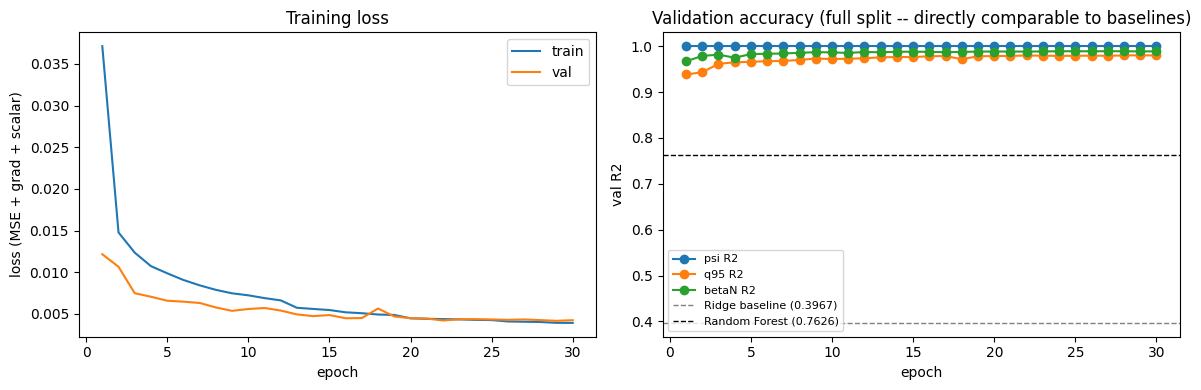

best epoch: psi_R2=1.0000


In [5]:
import matplotlib.pyplot as plt

epochs_ = [h["epoch"] for h in history]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(epochs_, [h["train_loss"] for h in history], label="train")
ax1.plot(epochs_, [h["val_loss"] for h in history], label="val")
ax1.set_xlabel("epoch"); ax1.set_ylabel("loss (MSE + grad + scalar)"); ax1.legend()
ax1.set_title("Training loss")

ax2.plot(epochs_, [h["psi_r2"] for h in history], label="psi R2", marker="o")
ax2.plot(epochs_, [h["q95_r2"] for h in history], label="q95 R2", marker="o")
ax2.plot(epochs_, [h["betan_r2"] for h in history], label="betaN R2", marker="o")
ax2.axhline(0.3967, color="gray", linestyle="--", linewidth=1, label="Ridge baseline (0.3967)")
ax2.axhline(0.7626, color="black", linestyle="--", linewidth=1, label="Random Forest (0.7626)")
ax2.set_xlabel("epoch"); ax2.set_ylabel("val R2"); ax2.legend(fontsize=8)
ax2.set_title("Validation accuracy (full split -- directly comparable to baselines)")

plt.tight_layout(); plt.show()
print(f"best epoch: psi_R2={max(h['psi_r2'] for h in history):.4f}")


In [8]:
import gc
import torch

# Drop references to the previous run's GPU-resident tensors/model so CUDA can reclaim them.
for name in ["model", "history", "X_tr", "Y_tr", "q95_tr", "betan_tr",
            "X_va", "Y_va", "q95_va", "betan_va"]:
    if name in globals():
        del globals()[name]

gc.collect()
torch.cuda.empty_cache()
print(f"GPU memory allocated: {torch.cuda.memory_allocated() / 1e9:.2f} GB")
print(f"GPU memory reserved:  {torch.cuda.memory_reserved() / 1e9:.2f} GB")

GPU memory allocated: 0.02 GB
GPU memory reserved:  0.04 GB


In [9]:
model2, history2 = train(
    n_shots_train=4929, n_shots_val=704, epochs=30, batch_size=256,
    load_workers=16, checkpoint_name="flux_conv_decoder_full_v2.pt",
    lr=5e-4,  # example change -- adjust whatever hyperparameter you're testing
)


[05:23:56] device: cuda (NVIDIA L4, 23.7 GB)
[05:23:56] loading 4929 train shots + 704 val shots from local parquet...


train shots:   0%|          | 0/4929 [00:00<?, ?shot/s]

val shots:   0%|          | 0/704 [00:00<?, ?shot/s]

[05:51:24]   1089024 train frames / 158282 val frames  (1648s)


/usr/local/lib/python3.13/dist-packages/numpy/_core/_methods.py:173: RuntimeWarning: overflow encountered in reduce
  arrmean = umr_sum(arr, axis, dtype, keepdims=True, where=where)


[05:52:14]   epoch  1/30  train_loss 0.05022  val_loss 0.01247  psi_R2 1.0000  q95_R2 0.9356  betaN_R2 0.9699  (33s)
[05:52:47]   epoch  2/30  train_loss 0.01572  val_loss 0.01432  psi_R2 1.0000  q95_R2 0.9215  betaN_R2 0.9764  (32s)
[05:53:19]   epoch  3/30  train_loss 0.01277  val_loss 0.00769  psi_R2 1.0000  q95_R2 0.9611  betaN_R2 0.9759  (32s)
[05:53:52]   epoch  4/30  train_loss 0.01088  val_loss 0.00735  psi_R2 1.0000  q95_R2 0.9619  betaN_R2 0.9807  (33s)
[05:54:24]   epoch  5/30  train_loss 0.00986  val_loss 0.00634  psi_R2 1.0000  q95_R2 0.9677  betaN_R2 0.9827  (33s)
[05:54:56]   epoch  6/30  train_loss 0.00905  val_loss 0.00807  psi_R2 1.0000  q95_R2 0.9570  betaN_R2 0.9841  (32s)
[05:55:28]   epoch  7/30  train_loss 0.00848  val_loss 0.00620  psi_R2 1.0000  q95_R2 0.9677  betaN_R2 0.9849  (32s)
[05:56:01]   epoch  8/30  train_loss 0.00808  val_loss 0.00679  psi_R2 1.0000  q95_R2 0.9655  betaN_R2 0.9804  (32s)
[05:56:33]   epoch  9/30  train_loss 0.00771  val_loss 0.00517  

In [10]:
m.evaluate(model2)


[06:09:49] loading 704 val shots for evaluation...


eval val shots:   0%|          | 0/704 [00:00<?, ?shot/s]

[06:11:15]   158282 val frames
[06:11:31] corrected eval: psi_R2=0.9930  q95_R2=0.9786  betaN_R2=0.9892  (158282 frames)


{'psi_r2': 0.9930427953746831,
 'q95_r2': 0.9786213778135131,
 'betan_r2': 0.9892191717143695,
 'n_val_shots': 704,
 'n_val_frames': 158282}

---

## Next steps

- `code/artifacts/models/flux_conv_decoder_full.pt` now exists (best val-loss checkpoint, full
  split). Still **not wired into `Predictor`/`06_build_submission.py`** -- that only loads
  joblib flux models outputting PCA coefficients, not a PyTorch state dict outputting ψ
  directly. Ask for that bridge once this checkpoint's val R2 looks competitive against the
  baselines plotted above.
- If this run OOMs even at float16 storage, the `n_shots_train` would need to drop, or the
  dataset would need to move off full-GPU-residency to a chunked/streaming load -- tell Claude
  if that happens.

install build-time deps (if not already present in this session):

In [11]:
!pip install -q datasets huggingface_hub python-dotenv


build DIII-D (874 shots):

In [12]:
!python {RUN_DIR}/06_build_submission.py --model "Conv Decoder (full)" --only diii_d_public_test


[06:15:37] === 06_build_submission  (max_shots=ALL) ===
[06:15:49]   flux model: Conv Decoder (full)   n_feat=149   ch2=yes
README.md: 100% 23.1k/23.1k [00:00<00:00, 20.6MB/s]
Resolving data files: 100% 7041/7041 [00:00<00:00, 24853.31it/s]
Resolving data files: 100% 874/874 [00:00<00:00, 25603.07it/s]
[06:18:31]   diii_d_public_test: 25 shots
[06:20:53]   diii_d_public_test: 50 shots
[06:23:24]   diii_d_public_test: 75 shots
[06:25:41]   diii_d_public_test: 100 shots
[06:28:06]   diii_d_public_test: 125 shots
[06:30:17]   diii_d_public_test: 150 shots
[06:32:34]   diii_d_public_test: 175 shots
[06:34:51]   diii_d_public_test: 200 shots
[06:37:09]   diii_d_public_test: 225 shots
[06:39:22]   diii_d_public_test: 250 shots
[06:41:48]   diii_d_public_test: 275 shots
[06:44:08]   diii_d_public_test: 300 shots
[06:46:11]   diii_d_public_test: 325 shots
[06:48:24]   diii_d_public_test: 350 shots
[06:50:49]   diii_d_public_test: 375 shots
[06:53:11]   diii_d_public_test: 400 shots
[06:55:25] 

build MAST (1206 shots):

In [13]:
!python {RUN_DIR}/06_build_submission.py --model "Conv Decoder (full)" --only mast_public_test

[07:39:04] === 06_build_submission  (max_shots=ALL) ===
[07:39:06]   flux model: Conv Decoder (full)   n_feat=149   ch2=yes
Resolving data files: 100% 7041/7041 [00:00<00:00, 25004.10it/s]
Resolving data files: 100% 1206/1206 [00:00<00:00, 25464.94it/s]
[07:40:08]   mast_public_test: 25 shots
[07:41:00]   mast_public_test: 50 shots
[07:41:52]   mast_public_test: 75 shots
[07:42:44]   mast_public_test: 100 shots
[07:43:38]   mast_public_test: 125 shots
[07:44:30]   mast_public_test: 150 shots
[07:45:22]   mast_public_test: 175 shots
[07:46:15]   mast_public_test: 200 shots
[07:47:07]   mast_public_test: 225 shots
[07:47:58]   mast_public_test: 250 shots
[07:48:51]   mast_public_test: 275 shots
[07:49:43]   mast_public_test: 300 shots
[07:50:35]   mast_public_test: 325 shots
[07:51:27]   mast_public_test: 350 shots
[07:52:19]   mast_public_test: 375 shots
[07:53:11]   mast_public_test: 400 shots
[07:54:03]   mast_public_test: 425 shots
[07:54:54]   mast_public_test: 450 shots
[07:55:46] 

In [14]:
!python {RUN_DIR}/07_validate_push.py --validate-only

[08:49:40] === 07_validate ===
[08:49:40] $ /usr/bin/python3 validate_submission.py /content/drive/MyDrive/EXPERIMENTS/FEC_NeurIPS/code/artifacts/submission/diii_d_public_test.npz --config diii_d_public_test --max-shots 0
Validating diii_d_public_test.npz against diii_d_public_test (expects DIII-D grid (65, 65))
  2622 arrays in the .npz; streaming reference inputs from the Hub …
Resolving data files: 100% 7041/7041 [00:00<00:00, 24840.62it/s]
Resolving data files: 100% 874/874 [00:00<00:00, 24882.55it/s]
Traceback (most recent call last):
  File "/usr/lib/python3.13/subprocess.py", line 1280, in wait
    return self._wait(timeout=timeout)
           ~~~~~~~~~~^^^^^^^^^^^^^^^^^
  File "/usr/lib/python3.13/subprocess.py", line 2085, in _wait
    (pid, sts) = self._try_wait(0)
                 ~~~~~~~~~~~~~~^^^
  File "/usr/lib/python3.13/subprocess.py", line 2043, in _try_wait
    (pid, sts) = os.waitpid(self.pid, wait_flags)
                 ~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^
KeyboardInt

In [15]:
import os
from dotenv import load_dotenv
load_dotenv(CODE_DIR / ".env")

!hf auth login --token {os.environ['HF_TOKEN']} --force

Hint: A new version of huggingface_hub (2.2.0) is available! You are using version 1.33.0.
To update, run: hf update
Hint: The `hf-cli` skill is not installed. Run `hf skills add -g` to teach your AI agents how to use the `hf` CLI.
The token has not been saved to the git credentials helper. Pass `add_to_git_credential=True` in this function directly or `--add-to-git-credential` if using via `hf`CLI if you want to set the git credential as well.
Token is valid (permission: write).
The token `FEC` has been saved to /root/.cache/huggingface/stored_tokens
Your token has been saved to /root/.cache/huggingface/token
Login successful.
Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


In [ ]:
!python {RUN_DIR}/07_validate_push.py --push

Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.
[10:00:57]   authenticated to HF Hub (fewer rate-limit retries while streaming reference data)
[10:00:57] === 07_validate ===
Validating diii_d_public_test.npz against diii_d_public_test (expects DIII-D grid (65, 65))
  2622 arrays in the .npz; streaming reference inputs from the Hub …
Resolving data files: 100% 7041/7041 [00:00<00:00, 25160.12it/s]
Resolving data files: 100% 874/874 [00:00<00:00, 25300.20it/s]
validating diii_d_public_test: 100% 874/874 [1:16:36<00:00,  5.26s/shot]

✓ OK — 874 shots, all shapes/keys/dtype valid for diii_d_public_test.
[11:17:57]   diii_d_public_test.npz: VALID
Validating mast_public_test.npz against mast_public_test (expects MAST grid (65, 65))
  3618 arrays in the .npz; streaming reference inputs from the Hub …
Resolving data files: 100% 7041/7041 [00:00<00:00, 25254.96it/s]
Resolving data files: 100% 1206/1206 [00:00<00:00